# Chapter 4 — Bayesian Inference: Estimating Hidden States

**Companion notebook for _Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems_.**

**Credits.** Book author and scientific/editorial direction: **Khalid M. Mosalam** (UC Berkeley). Original companion notebook development: **Fan Hu**; additional notebooks and shared numerical implementations: **Ziad K. Mosalam**. This Chapter 4 notebook builds on the book's radar example and discrete MAP/MMSE exercise. The [README](../README.md) and Git history document the project-wide contributions.

**Scope.** All values below are synthetic teaching examples, not measured radar or infrastructure data. The Gaussian numerical case uses the same prior, observation, and variances as Chapter 4. Run the cells in order; results and publication-quality PDF/PNG figures are saved under `results/` and `figures/`.

The central question is not just *what is the best single estimate?* It is *what does the posterior distribution tell us about an unobserved state and its remaining uncertainty?*

## 1. Radar-based hidden-state estimation

Let \(x\) be an unknown target position, with a Gaussian prior and noisy radar measurement:

\[
x\sim\mathcal N(5,1),\qquad z\mid x\sim\mathcal N(x,0.5),\qquad z=6.
\]

The first Gaussian parameter is the **mean** and the second is the **variance**. Positions are in meters and variances in square meters. The observation noise is assumed independent of the prior state uncertainty.

The posterior precision (inverse variance) equals the sum of the prior and measurement precisions:

\[
\sigma_{\mathrm{post}}^{-2}=\sigma_{\mathrm{prior}}^{-2}+\sigma_{\mathrm{meas}}^{-2},
\quad
\mu_{\mathrm{post}}=\sigma_{\mathrm{post}}^{2}
\left(\frac{\mu_{\mathrm{prior}}}{\sigma_{\mathrm{prior}}^{2}}+
\frac{z}{\sigma_{\mathrm{meas}}^{2}}\right).
\]

The posterior mean should be between 5 and 6 m, closer to the more precise radar measurement.

In [1]:
from pathlib import Path
import sys, json, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))
(root / "figures").mkdir(exist_ok=True)
(root / "results").mkdir(exist_ok=True)
plt.style.use(str(root / "notebooks" / "book.mplstyle"))

from robotics_book.chapter_examples import run_example
baseline = run_example("bayesian-inference", root=root)
print("Existing reproducible chapter calculation:")
print(json.dumps(baseline["values"], indent=2))

Existing reproducible chapter calculation:
{
  "posterior_mean": 5.666666666666667,
  "posterior_variance": 0.33333333333333337
}


In [2]:
mu_prior, var_prior = 5.0, 1.0
z, var_meas = 6.0, 0.5

precision_prior, precision_meas = 1 / var_prior, 1 / var_meas
var_post = 1 / (precision_prior + precision_meas)
mu_post = var_post * (precision_prior * mu_prior + precision_meas * z)

assert math.isclose(mu_post, 17 / 3, abs_tol=1e-12)
assert math.isclose(var_post, 1 / 3, abs_tol=1e-12)
assert math.isclose(mu_post, baseline["values"]["posterior_mean"], abs_tol=1e-12)
assert math.isclose(var_post, baseline["values"]["posterior_variance"], abs_tol=1e-12)

print(f"Prior: mean = {mu_prior:.4f} m; variance = {var_prior:.4f} m^2")
print(f"Measurement: z = {z:.4f} m; variance = {var_meas:.4f} m^2")
print(f"Posterior: mean = {mu_post:.4f} m; variance = {var_post:.4f} m^2")
print(f"Gaussian MAP = MMSE = {mu_post:.4f} m")

Prior: mean = 5.0000 m; variance = 1.0000 m^2
Measurement: z = 6.0000 m; variance = 0.5000 m^2
Posterior: mean = 5.6667 m; variance = 0.3333 m^2
Gaussian MAP = MMSE = 5.6667 m


## 2. Prior, likelihood, and posterior

The figure below compares all three components of Bayes' theorem. The **likelihood curve** is plotted as a function of the candidate state \(x\) for the *fixed observed value* \(z=6\); it is not a posterior distribution and need not integrate to one in a general model. In this Gaussian location example it has the same shape as \(\mathcal N(6,0.5)\).

The posterior is narrower than either of the other two curves. Its mean is \(17/3\approx 5.667\) m.

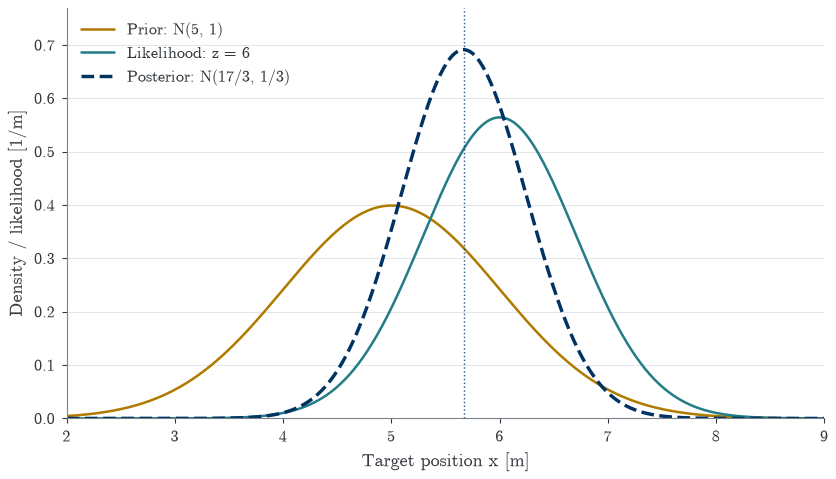

In [3]:
x = np.linspace(2.0, 9.0, 500)
prior_density = norm.pdf(x, loc=mu_prior, scale=math.sqrt(var_prior))
likelihood_x = norm.pdf(z, loc=x, scale=math.sqrt(var_meas))
posterior_density = norm.pdf(x, loc=mu_post, scale=math.sqrt(var_post))

fig, ax = plt.subplots(figsize=(6.4, 3.65), layout="constrained")
ax.plot(x, prior_density, color="#B17A00", label="Prior: N(5, 1)")
ax.plot(x, likelihood_x, color="#247C86", label="Likelihood: z = 6")
ax.plot(x, posterior_density, color="#003262", linestyle="--",
        label="Posterior: N(17/3, 1/3)", linewidth=1.9)
ax.axvline(mu_post, color="#003262", linestyle=":", linewidth=0.8, alpha=0.8)
ax.set(xlabel="Target position x [m]", ylabel="Density / likelihood [1/m]", xlim=(2, 9), ylim=(0, 0.77))
ax.legend(loc="upper left")
ax.grid(axis="y")
fig.savefig(root / "figures" / "bayesian-inference-three-densities.pdf",
            metadata={"CreationDate": None, "ModDate": None})
fig.savefig(root / "figures" / "bayesian-inference-three-densities.png", dpi=200)
plt.show()

## 3. MAP versus MMSE: a discrete posterior

For the Gaussian example, the **MAP** estimate (posterior mode) and **MMSE** estimate (posterior mean) coincide at 5.667 m. They need not coincide for other posterior distributions.

Consider the Chapter 4 discrete example:

| State \(x\) | 0 | 1 | 3 |
|:---|---:|---:|---:|
| Posterior probability \(P(x\mid z)\) | 0.20 | 0.50 | 0.30 |

The MAP estimate selects the **most probable single state**. The MMSE estimate minimizes posterior expected **squared error**; it may lie between supported discrete states. In this example its value is not one of the three possible states. This is why the loss function and the full posterior matter.

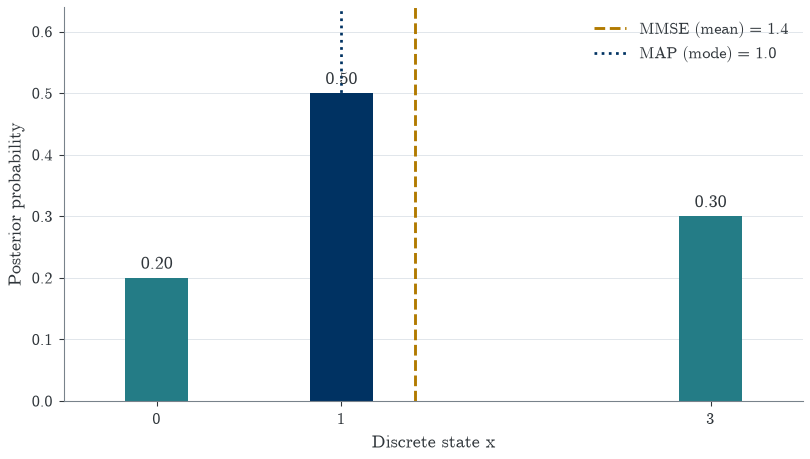

MAP estimate: 1.0; expected squared error: 1.400
MMSE estimate: 1.4; expected squared error: 1.240
Note: the MMSE value is not a possible discrete state, but is valid as an unconstrained numerical estimate.


In [4]:
states = np.array([0.0, 1.0, 3.0])
probs = np.array([0.2, 0.5, 0.3])
assert math.isclose(float(probs.sum()), 1.0, abs_tol=1e-12)

map_estimate = float(states[np.argmax(probs)])
mmse_estimate = float(np.dot(states, probs))
map_squared_error = float(np.dot(probs, (states - map_estimate) ** 2))
mmse_squared_error = float(np.dot(probs, (states - mmse_estimate) ** 2))
assert map_estimate == 1.0
assert math.isclose(mmse_estimate, 1.4, abs_tol=1e-12)
assert mmse_squared_error < map_squared_error

fig, ax = plt.subplots(figsize=(6.2, 3.5), layout="constrained")
bars = ax.bar(states, probs, width=0.34, color=["#247C86", "#003262", "#247C86"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(mmse_estimate, color="#B17A00", linestyle="--", linewidth=1.6,
           label=f"MMSE (mean) = {mmse_estimate:.1f}")
ax.axvline(map_estimate, color="#003262", linestyle=":", linewidth=1.5,
           label=f"MAP (mode) = {map_estimate:.1f}")
ax.set(xlabel="Discrete state x", ylabel="Posterior probability",
       ylim=(0, 0.64), xlim=(-0.5, 3.5), xticks=[0, 1, 3])
ax.legend(loc="upper right")
ax.grid(axis="y")
fig.savefig(root / "figures" / "bayesian-inference-map-mmse.pdf",
            metadata={"CreationDate": None, "ModDate": None})
fig.savefig(root / "figures" / "bayesian-inference-map-mmse.png", dpi=200)
plt.show()
print(f"MAP estimate: {map_estimate:.1f}; expected squared error: {map_squared_error:.3f}")
print(f"MMSE estimate: {mmse_estimate:.1f}; expected squared error: {mmse_squared_error:.3f}")
print("Note: the MMSE value is not a possible discrete state, but is valid as an unconstrained numerical estimate.")

## 4. Estimation is not decision-making

A point estimator is not automatically the optimal engineering action. The book's inspection-robot example assigns a loss of 100 units to continuing in an unsafe state, and 10 units to stopping regardless of the true state.

At posterior unsafe probability \(p=0.15\), the expected loss of continuing is \(100p=15\), while the loss of stopping is 10. Stopping minimizes expected loss. The decision switches at \(p=0.10\), with a tie at the threshold.

In [5]:
unsafe_probability = 0.15
continue_loss_unsafe, stop_cost = 100.0, 10.0
expected_continue = continue_loss_unsafe * unsafe_probability
expected_stop = stop_cost
threshold = stop_cost / continue_loss_unsafe
action = "stop for inspection" if expected_stop < expected_continue else "continue"
assert math.isclose(threshold, 0.1, abs_tol=1e-12)
assert action == "stop for inspection"
print(f"Expected loss, continue: {expected_continue:.1f}")
print(f"Expected loss, stop: {expected_stop:.1f}")
print(f"Decision threshold: p = {threshold:.2f} (tie at the threshold)")
print(f"Preferred action at p = {unsafe_probability:.2f}: {action}")

extended = {
    "topic": "bayesian-inference",
    "data_status": "synthetic teaching examples",
    "radar": {"prior_mean_m": mu_prior, "prior_variance_m2": var_prior,
              "radar_reading_m": z, "measurement_variance_m2": var_meas,
              "posterior_mean_m": mu_post, "posterior_variance_m2": var_post},
    "discrete_estimation": {"states": states.tolist(), "posterior": probs.tolist(),
                             "map": map_estimate, "mmse": mmse_estimate,
                             "map_squared_error": map_squared_error,
                             "mmse_squared_error": mmse_squared_error},
    "decision": {"unsafe_probability": unsafe_probability,
                 "expected_continue_loss": expected_continue,
                 "expected_stop_loss": expected_stop, "switch_threshold": threshold}
}
(root / "results" / "bayesian-inference-extended.json").write_text(
    json.dumps(extended, indent=2) + "\n", encoding="utf-8")

Expected loss, continue: 15.0
Expected loss, stop: 10.0
Decision threshold: p = 0.10 (tie at the threshold)
Preferred action at p = 0.15: stop for inspection


700

## 5. Suggested experiments

1. **Measurement quality:** Increase the radar measurement variance from 0.5 to 2 m². How do the posterior mean and variance change? What happens as the variance becomes very large?
2. **Prior quality:** Increase the prior variance from 1 to 4 m². Explain why the posterior shifts toward the measurement.
3. **MAP versus MMSE:** Change the three discrete probabilities while keeping their sum equal to 1. Does the MAP estimate move discontinuously? Does the MMSE estimate move continuously?
4. **Decision sensitivity:** Vary the unsafe-state probability around 0.10. Compare the optimal action with either point estimate.

**Limitations:** These examples assume specified distributions and noise variances. A visually narrow posterior is not evidence that the assumed measurement likelihood or prior is adequately calibrated. A complete field application would require calibration data, model checks, and an independent assessment of performance.